In [198]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import random
import math

from sklearn.metrics import roc_auc_score, roc_curve, auc, confusion_matrix
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

In [199]:
df = pd.read_csv('FouilleDeDonnees.Achats.ExamenJanvier2018.1.csv')

df.head()

,HHKEY,ZIP_CODE,REC,FRE,MON,CC_CARD,AVRG,PC_CALC20,PSWEATERS,PKNIT_TOPS,...,VALPHON,WEB,MAILED,RESPONDED,RESPONSERATE,HI,LTFREDAY,CLUSTYPE,PERCRET,RESP
0,9955617749583,33116,4,4,236.98,0,59.24,11,0.12,0.00,...,Y,0,10,2,20.00,41.19,49.80,50,0.000000,0
1,9955640904937,72015,77,3,233.94,0,77.98,11,0.00,0.00,...,Y,0,1,0,0.00,33.60,84.83,18,0.000000,0
2,9955623792337,44141,60,2,1014.94,1,507.47,16,0.14,0.00,...,Y,0,0,0,0.00,16.92,63.44,3,0.000000,1
3,9955645403406,78218,54,11,1217.95,1,110.72,19,0.16,0.07,...,Y,0,3,1,33.33,12.91,15.71,12,0.006158,0
4,9955648623881,91506,26,5,334.21,1,66.84,11,0.09,0.08,...,Y,0,6,1,16.67,16.09,54.85,12,0.000000,0


In [200]:
def transform(x):
    if x == "Y":
        return 1
    else:
        return 0

df['VALPHON'] = df['VALPHON'].apply(transform)

X = df.drop(columns=["HHKEY", "RESP", "ZIP_CODE", "STORELOY", 'PC_CALC20', 'CLUSTYPE', 'STYLES'])

y = df["RESP"]

In [201]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)

model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

y_test_pred = model.predict_proba(X_test)[:,1]

print(f"Taille de X_train : {X_train.shape}")
print(f"Taille de X_test  : {X_test.shape}")

Taille de X_train : (13913, 44)
Taille de X_test  : (3479, 44)


c:\Users\xavie\anaconda3\anacondaa\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


AUC:0.8523358805140675


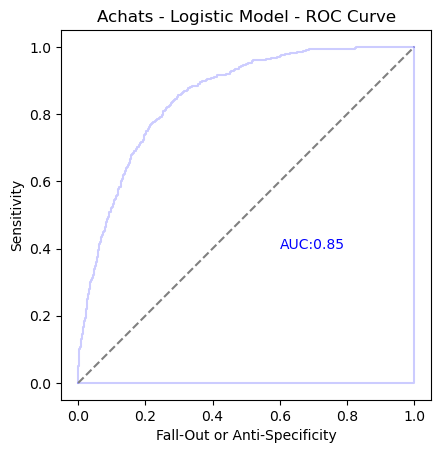

In [202]:
fpr,tpr,thresholds = roc_curve(y_test,y_test_pred)
roc_auc = auc(fpr,tpr)

score_df = pd.DataFrame()
score_df['fallout']=fpr
score_df['sensitivity']=tpr
score_df['T']=thresholds

score_df.head()

print('AUC:{}'.format(roc_auc))

plt.figure()
plt.axes().set_aspect('equal')

plt.plot(fpr,tpr,'-',color='blue',alpha=0.2)
plt.plot([0,1,1],[0,0,1],'-',color='blue',alpha=0.2)
plt.plot([0,1],[0,1],'--',color='grey')

plt.title('Achats - Logistic Model - ROC Curve')
plt.xlabel('Fall-Out or Anti-Specificity')
plt.ylabel('Sensitivity')

plt.text(0.6,0.4,"AUC:{0:.2f}".format(roc_auc),color='blue')

plt.show()